### 4.4 Definição do Hardware

In [1]:
# Verificar o status da GPU
!nvidia-smi

Fri Jul 31 19:07:33 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA RTX PRO 6000 Blac...    Off |   00000000:05:00.0 Off |                    0 |
| N/A   29C    P0             48W /  600W |       0MiB /  97887MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

### 4.5 Configuração do Ambiente (SSD e Dependências)

In [2]:
# Instalar bibliotecas necessárias para manipulação de dados e modelos
!pip install torch torchvision yacs tqdm
import torch
import torchvision
print(f"PyTorch Versão: {torch.__version__} | Torchvision Versão: {torchvision.__version__}")

PyTorch Versão: 2.11.0+cu128 | Torchvision Versão: 0.26.0+cu128


### Conexão com a Nuvem (Google Drive)

In [3]:
from google.colab import drive
import os

# Montar o Google Drive
drive.mount('/content/drive')

# Desmontar o Google Drive
# drive.flush_and_unmount()

Mounted at /content/drive


### 4.3 Pré-processamento dos Datasets

In [4]:
import os
import shutil
import glob
import torch
import xml.etree.ElementTree as ET
from PIL import Image
from torchvision.transforms import transforms as T

# ==============================================================================
# 1. LIMPEZA E DESCOMPACTAÇÃO
# ==============================================================================
caminho_zip_drive = "/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/SSD_dataset.zip"
pasta_local_vm = "/content/SSD_dataset"
zip_local_vm = "/content/SSD_dataset.zip"

print("🧹 Limpando ambiente...")
if os.path.exists(pasta_local_vm):
    shutil.rmtree(pasta_local_vm)
if os.path.exists(zip_local_vm):
    os.remove(zip_local_vm)

if not os.path.exists(caminho_zip_drive):
    raise FileNotFoundError(f"❌ Arquivo não encontrado no Drive: {caminho_zip_drive}")

print("🚚 Copiando o SSD_dataset.zip...")
shutil.copy2(caminho_zip_drive, zip_local_vm)

print("⚡ Descompactando...")
!unzip -q {zip_local_vm} -d {pasta_local_vm}

if os.path.exists(zip_local_vm):
    os.remove(zip_local_vm)

# ==============================================================================
# 2. AUTO-DETECÇÃO DE PASTAS (O RAIO-X)
# ==============================================================================
root_dataset = None

# Procura dinamicamente onde estão as pastas "images" e "annotations_xml"
for root, dirs, files in os.walk(pasta_local_vm):
    if "images" in dirs and "annotations_xml" in dirs:
        root_dataset = root
        break

if root_dataset is None:
    raise ValueError("❌ Não foi possível encontrar as pastas 'images' e 'annotations_xml' dentro do ZIP!")

print(f"🎯 Pastas de imagens e anotações localizadas com sucesso em: {root_dataset}")

# ==============================================================================
# 3. CLASSE DATASET PARA LER PASCAL VOC (XML) E REDIMENSIONAR CAIXAS
# ==============================================================================
class CustomSSDDataset(torch.utils.data.Dataset):
    def __init__(self, root, split, transforms=None):
        self.root = root
        self.split = split
        self.transforms = transforms

        self.img_dir = os.path.join(root, "images", split)
        self.xml_dir = os.path.join(root, "annotations_xml", split)

        # Pega .jpg e .JPG
        self.img_files = sorted(glob.glob(os.path.join(self.img_dir, "*.jpg")) + glob.glob(os.path.join(self.img_dir, "*.JPG")))

        self.class_to_id = {
            'person': 1,
            'bicycle': 2,
            'car': 3,
            'motorcycle': 4,
            'bus': 5
        }

    def __getitem__(self, idx):
        img_path = self.img_files[idx]
        img = Image.open(img_path).convert("RGB")
        largura_orig, altura_orig = img.size

        xml_name = os.path.basename(img_path).replace('.jpg', '.xml').replace('.JPG', '.xml')
        xml_path = os.path.join(self.xml_dir, xml_name)

        boxes = []
        labels = []

        if os.path.exists(xml_path):
            tree = ET.parse(xml_path)
            root_xml = tree.getroot()

            for obj in root_xml.findall('object'):
                nome_classe = obj.find('name').text

                if nome_classe in self.class_to_id:
                    bndbox = obj.find('bndbox')
                    xmin = float(bndbox.find('xmin').text)
                    ymin = float(bndbox.find('ymin').text)
                    xmax = float(bndbox.find('xmax').text)
                    ymax = float(bndbox.find('ymax').text)

                    # Ajuste de escala (300x300) exigido pelo SSD
                    xmin = (xmin / largura_orig) * 300.0
                    ymin = (ymin / altura_orig) * 300.0
                    xmax = (xmax / largura_orig) * 300.0
                    ymax = (ymax / altura_orig) * 300.0

                    # Clipping
                    xmin = max(0.0, min(xmin, 300.0))
                    ymin = max(0.0, min(ymin, 300.0))
                    xmax = max(0.0, min(xmax, 300.0))
                    ymax = max(0.0, min(ymax, 300.0))

                    if (xmax - xmin) > 1.0 and (ymax - ymin) > 1.0:
                        boxes.append([xmin, ymin, xmax, ymax])
                        labels.append(self.class_to_id[nome_classe])

        if len(boxes) == 0:
            boxes = torch.zeros((0, 4), dtype=torch.float32)
            labels = torch.zeros((0,), dtype=torch.int64)
        else:
            boxes = torch.as_tensor(boxes, dtype=torch.float32)
            labels = torch.as_tensor(labels, dtype=torch.int64)

        target = {}
        target["boxes"] = boxes
        target["labels"] = labels

        if self.transforms:
            img = self.transforms(img)

        return img, target

    def __len__(self):
        return len(self.img_files)

# ==============================================================================
# 4. DATALOADERS E TRANSFORMAÇÕES
# ==============================================================================
dataset_transforms = T.Compose([
    T.Resize((300, 300)),
    T.ToTensor(),
])

def collate_fn(batch):
    return tuple(zip(*batch))

# Passando o caminho dinâmico que o código detectou
train_dataset = CustomSSDDataset(root_dataset, "train", transforms=dataset_transforms)
val_dataset   = CustomSSDDataset(root_dataset, "val", transforms=dataset_transforms)
test_dataset  = CustomSSDDataset(root_dataset, "test", transforms=dataset_transforms)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=256, shuffle=True, collate_fn=collate_fn, num_workers=16)
val_loader   = torch.utils.data.DataLoader(val_dataset, batch_size=256, shuffle=False, collate_fn=collate_fn, num_workers=16)
test_loader  = torch.utils.data.DataLoader(test_dataset, batch_size=256, shuffle=False, collate_fn=collate_fn, num_workers=16)

print("=" * 60)
print("✅ DataLoaders criados com suporte a anotações XML (Pascal VOC)!")
print(f"📊 Amostras de Treino: {len(train_dataset)}")
print(f"📊 Amostras de Validação: {len(val_dataset)}")
print(f"📊 Amostras de Teste: {len(test_dataset)}")
print("=" * 60)

🧹 Limpando ambiente...
🚚 Copiando o SSD_dataset.zip...
⚡ Descompactando...
🎯 Pastas de imagens e anotações localizadas com sucesso em: /content/SSD_dataset/SSD_dataset
✅ DataLoaders criados com suporte a anotações XML (Pascal VOC)!
📊 Amostras de Treino: 8265
📊 Amostras de Validação: 1033
📊 Amostras de Teste: 1034


### 4.6 Definição de Hiperparâmetros e 4.7 Treinamento do Modelo

In [5]:
import torch
from torchvision.models.detection import ssd300_vgg16
from torchvision.models.detection.ssd import SSDClassificationHead # <-- Importação corrigida
from torch.optim.lr_scheduler import LinearLR
from datetime import datetime
from tqdm import tqdm
import os
import time

# 1. Configurações de salvamento
agora = datetime.now()
nome_treino_ssd = agora.strftime("Treino_ssd_%Y-%m-%d_%Hh%M")
diretorio_drive_ssd = "/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_SSD"
os.makedirs(f"{diretorio_drive_ssd}/{nome_treino_ssd}/weights", exist_ok=True)

print(f"🚀 Iniciando SSD. Resultados salvos em: {diretorio_drive_ssd}/{nome_treino_ssd}")

num_classes = 6
print(f"📌 Cabeçalho SSD configurado para {num_classes} classes (incluindo background).")

# 2. Inicializar o Modelo SSD300 com pesos base (COCO)
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
model = ssd300_vgg16(weights='DEFAULT')

# --- O SEGREDO DO TRANSFER LEARNING NO SSD ---
# Substituímos APENAS o classificador.
# Isso preserva os pesos do "Regression Head" (que já sabe achar caixas) e do Backbone.
in_channels = [512, 1024, 512, 256, 256, 256]
num_anchors = [4, 6, 6, 6, 4, 4]
model.head.classification_head = SSDClassificationHead(in_channels, num_anchors, num_classes)
model.to(device)

# 3. Otimizador, Scheduler de Warmup e Hiperparâmetros
params = [p for p in model.parameters() if p.requires_grad]
# Ajuste fino da LR para Transfer Learning
optimizer = torch.optim.SGD(params, lr=0.002, momentum=0.9, weight_decay=0.0005)

# Warmup ajustado para 500 iterações
warmup_scheduler = LinearLR(optimizer, start_factor=0.001, total_iters=500)

# --- VARIÁVEIS DO EARLY STOPPING ---
epochs = 200            # Limite alto, o modelo vai parar sozinho antes disso
patience = 30            # Tolerância: quantas épocas esperar sem melhoria
epochs_no_improve = 0    # Contador de épocas frustradas
best_val_loss = float('inf') # Começa infinito para a primeira época ser sempre a melhor

# --- MARCAÇÃO DE INÍCIO DO TREINAMENTO TOTAL ---
tempo_inicio_total = time.time()

# 4. Loop de Treinamento
for epoch in range(epochs):
    tempo_inicio_epoca = time.time()

    # ==========================================
    # FASE 1: TREINO
    # ==========================================
    model.train()
    epoch_train_loss = 0
    progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} [Train]")

    for images, targets in progress_bar:
        images = list(image.to(device) for image in images)
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        if any(len(t["boxes"]) == 0 for t in targets):
            continue

        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())

        optimizer.zero_grad()
        losses.backward()

        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        if epoch == 0 or epoch == 1:
            warmup_scheduler.step()

        epoch_train_loss += losses.item()
        progress_bar.set_postfix(loss=losses.item())

    media_train_loss = epoch_train_loss / len(train_loader)

    # ==========================================
    # FASE 2: VALIDAÇÃO (O Motor do Early Stopping)
    # ==========================================
    epoch_val_loss = 0

    with torch.no_grad(): # Não calcula gradientes na validação
        val_bar = tqdm(val_loader, desc=f"Epoch {epoch+1}/{epochs} [Val]", leave=False)

        for images, targets in val_bar:
            images = list(image.to(device) for image in images)
            targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

            # ATENÇÃO: O SSD do torchvision precisa ficar em .train()
            # para devolver o dicionário de loss em vez das caixas finais.
            model.train()

            loss_dict = model(images, targets)
            losses = sum(loss for loss in loss_dict.values())
            epoch_val_loss += losses.item()

    media_val_loss = epoch_val_loss / len(val_loader)

    # ==========================================
    # FASE 3: LÓGICA DE PACIÊNCIA E SALVAMENTO
    # ==========================================
    tempo_fim_epoca = time.time()
    minutos_ep, segundos_ep = divmod(tempo_fim_epoca - tempo_inicio_epoca, 60)

    print(f"📈 Fim da Epoch {epoch+1} - Train Loss: {media_train_loss:.4f} | Val Loss: {media_val_loss:.4f}")
    print(f"⏱️ Tempo: {int(minutos_ep)}m {int(segundos_ep)}s")

    # Salva sempre a última época
    torch.save(model.state_dict(), f"{diretorio_drive_ssd}/{nome_treino_ssd}/weights/last.pt")

    # A lógica principal de Paciência:
    if media_val_loss < best_val_loss:
        # Se melhorou, salva o modelo e zera o contador de paciência
        best_val_loss = media_val_loss
        epochs_no_improve = 0
        melhor_epoca = epoch + 1
        torch.save(model.state_dict(), f"{diretorio_drive_ssd}/{nome_treino_ssd}/weights/best.pt")
        print("🏆 Melhor modelo atualizado (Baseado na Val Loss) e salvo no Drive!")
    else:
        # Se piorou, aumenta o contador
        epochs_no_improve += 1
        print(f"⚠️ Sem melhora na Val Loss há {epochs_no_improve} época(s).")

        # Se o contador atingir a paciência, interrompe o treino
        if epochs_no_improve >= patience:
            print("-" * 50)
            print(f"🛑 EARLY STOPPING ACIONADO! O modelo parou de generalizar.")
            print(f"O melhor peso salvo está em 'best.pt' (da época {epoch + 1 - patience}).")
            break # Encerra o loop 'for epoch in range(epochs)'

    print("-" * 50)

# 5. Finalização
tempo_fim_total = time.time()
duracao_total = tempo_fim_total - tempo_inicio_total
minutos_tot, segundos_tot = divmod(duracao_total, 60)

print("\n" + "=" * 60)
print("✅ Treinamento finalizado!")
print(f"⏱️ Tempo Total do Treinamento: {int(minutos_tot)}m {int(segundos_tot)}s")
print("=" * 60)

🚀 Iniciando SSD. Resultados salvos em: /content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_SSD/Treino_ssd_2026-07-31_19h08
📌 Cabeçalho SSD configurado para 6 classes (incluindo background).
Downloading: "https://download.pytorch.org/models/ssd300_vgg16_coco-b556d3b4.pth" to /root/.cache/torch/hub/checkpoints/ssd300_vgg16_coco-b556d3b4.pth


100%|██████████| 136M/136M [00:00<00:00, 296MB/s]
Epoch 1/200 [Train]: 100%|██████████| 33/33 [00:29<00:00,  1.13it/s, loss=17.4]


📈 Fim da Epoch 1 - Train Loss: 18.9817 | Val Loss: 17.7357
⏱️ Tempo: 0m 32s
🏆 Melhor modelo atualizado (Baseado na Val Loss) e salvo no Drive!
--------------------------------------------------


Epoch 2/200 [Train]: 100%|██████████| 33/33 [00:27<00:00,  1.19it/s, loss=14]


📈 Fim da Epoch 2 - Train Loss: 15.5498 | Val Loss: 13.6876
⏱️ Tempo: 0m 30s
🏆 Melhor modelo atualizado (Baseado na Val Loss) e salvo no Drive!
--------------------------------------------------


Epoch 3/200 [Train]: 100%|██████████| 33/33 [00:27<00:00,  1.19it/s, loss=11.2]


... (391 outputs left out)

Epoch 199/200 [Train]: 100%|██████████| 33/33 [00:27<00:00,  1.19it/s, loss=3.25]


📈 Fim da Epoch 199 - Train Loss: 3.1758 | Val Loss: 3.4983
⏱️ Tempo: 0m 30s
🏆 Melhor modelo atualizado (Baseado na Val Loss) e salvo no Drive!
--------------------------------------------------


Epoch 200/200 [Train]: 100%|██████████| 33/33 [00:27<00:00,  1.19it/s, loss=3.09]
                                                                  

📈 Fim da Epoch 200 - Train Loss: 3.1701 | Val Loss: 3.4996
⏱️ Tempo: 0m 30s
⚠️ Sem melhora na Val Loss há 1 época(s).
--------------------------------------------------

✅ Treinamento finalizado!
⏱️ Tempo Total do Treinamento: 104m 1s


### 4.7 Inferência com o Conjunto de Testes

In [6]:
!pip install torchmetrics -U

import os
import time
import torch
from torchvision.ops import box_iou
from torchmetrics.detection.mean_ap import MeanAveragePrecision

print("🔍 Testando o modelo SSD contra dados nunca vistos (Conjunto de Teste)...")

# =====================================================
# Carregar o melhor modelo
# =====================================================

caminho_melhor_peso = f"{diretorio_drive_ssd}/{nome_treino_ssd}/weights/best.pt"
print(f"Melhor peso do Drive: {caminho_melhor_peso}")

model.load_state_dict(torch.load(caminho_melhor_peso))
model.eval()

# =====================================================
# Métricas
# =====================================================

metric = MeanAveragePrecision(iou_type="bbox")

tempos_inferencia = []

tp = 0
fp = 0
fn = 0

IOU_THRESHOLD = 0.5
SCORE_THRESHOLD = 0.5

with torch.no_grad():

    for images, targets in test_loader:

        images = [img.to(device) for img in images]

        # ---------- Ground Truth ----------
        targets_metric = []

        for t in targets:
            targets_metric.append({
                "boxes": t["boxes"].to(device),
                "labels": t["labels"].to(device)
            })

        # ---------- Inferência ----------
        start_time = time.time()

        outputs = model(images)

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        end_time = time.time()

        tempos_inferencia.append(
            (end_time - start_time) / len(images)
        )

        # ---------- Predições ----------
        preds_metric = []

        for out in outputs:

            preds_metric.append({
                "boxes": out["boxes"].to(device),
                "scores": out["scores"].to(device),
                "labels": out["labels"].to(device)
            })

        metric.update(preds_metric, targets_metric)

        # ==================================================
        # Precision e Recall
        # ==================================================

        for output, target in zip(outputs, targets):

            pred_boxes = output["boxes"].cpu()
            pred_scores = output["scores"].cpu()
            pred_labels = output["labels"].cpu()

            gt_boxes = target["boxes"].cpu()
            gt_labels = target["labels"].cpu()

            keep = pred_scores >= SCORE_THRESHOLD

            pred_boxes = pred_boxes[keep]
            pred_labels = pred_labels[keep]

            matched_gt = set()

            for pred_box, pred_label in zip(pred_boxes, pred_labels):

                melhor_iou = 0
                melhor_gt = -1

                for i, (gt_box, gt_label) in enumerate(zip(gt_boxes, gt_labels)):

                    if i in matched_gt:
                        continue

                    # Classe diferente não pode casar
                    if pred_label != gt_label:
                        continue

                    iou = box_iou(
                        pred_box.unsqueeze(0),
                        gt_box.unsqueeze(0)
                    )[0, 0].item()

                    if iou > melhor_iou:
                        melhor_iou = iou
                        melhor_gt = i

                if melhor_iou >= IOU_THRESHOLD:
                    tp += 1
                    matched_gt.add(melhor_gt)
                else:
                    fp += 1

            fn += len(gt_boxes) - len(matched_gt)

# =====================================================
# Resultados
# =====================================================

metrics_result = metric.compute()

precision = tp / (tp + fp + 1e-8)
recall = tp / (tp + fn + 1e-8)

precision *= 100
recall *= 100

map_50 = metrics_result["map_50"].item() * 100
map_50_95 = metrics_result["map"].item() * 100
mar_100 = metrics_result["mar_100"].item() * 100

tempo_medio_ms = (
    sum(tempos_inferencia) / len(tempos_inferencia)
) * 1000

print("=" * 70)
print("📊 Avaliação Final no Conjunto de Testes - SSD300")
print(f"⏱️ Tempo Médio:                 {tempo_medio_ms:.2f} ms/imagem")
print("-" * 70)
print("💡 Precision: TP / (TP + FP)")
print("💡 Recall: TP / (TP + FN)")
print("-" * 70)
print(f"🎯 Precisão:                    {precision:.2f}%")
print(f"🎯 Recall:                      {recall:.2f}%")
print(f"🎯 Recall Médio (mAR@100):      {mar_100:.2f}%")
print(f"🎯 mAP@0.5:                     {map_50:.2f}%")
print(f"🎯 mAP@0.5:0.95:                {map_50_95:.2f}%")
print("=" * 70)

# =====================================================
# Salvar relatório
# =====================================================

with open(
    f"{diretorio_drive_ssd}/{nome_treino_ssd}/resultado_teste.txt",
    "w",
    encoding="utf-8",
) as f:

    f.write("Métricas de Avaliação Final - SSD300\n")
    f.write(f"Data e Hora: {agora.strftime('%Y-%m-%d %H:%M:%S')}\n")
    f.write(f"Quantidade de épocas: {epochs}\n")
    # --- CORREÇÃO DAS ÉPOCAS E EARLY STOPPING ---
    # Assume que a variável 'melhor_epoca' foi declarada no treino.
    # 'epoch' contém a última época em que o loop rodou antes do Early Stopping cortar.
    try:
        f.write(f"Melhor peso encontrado na época: {melhor_epoca}\n")
        f.write(f"Treinamento interrompido na época: {epoch + 1} (Limite era {epochs})\n")
    except NameError:
        f.write(f"Número Limite de Épocas Configurado: {epochs}\n")

    f.write(f"Tempo Total de Treinamento: {int(minutos_tot / 60)}h {int(minutos_tot % 60)}m {int(segundos_tot)}s\n")
    f.write(f"Tempo Total de Treinamento em minutos: {minutos_tot:.2f} min\n")
    f.write("-" * 60 + "\n\n")

    f.write("Precisão = TP / (TP + FP)\n")
    f.write("Recall = TP / (TP + FN)\n")
    f.write("mAP = Média da Average Precision (COCO)\n\n")

    f.write(f"Tempo médio por imagem: {tempo_medio_ms:.2f} ms\n")
    f.write(f"Precisão:               {precision:.2f}%\n")
    f.write(f"Recall:                 {recall:.2f}%\n")
    f.write(f"Recall Médio (mAR@100): {mar_100:.2f}%\n")
    f.write(f"mAP@0.5:                {map_50:.2f}%\n")
    f.write(f"mAP@0.5:0.95:           {map_50_95:.2f}%\n")

print("💾 Arquivo contendo as métricas gerado com sucesso no Drive!")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 36.3 MB/s eta 0:00:00
🔍 Testando o modelo SSD contra dados nunca vistos (Conjunto de Teste)...
Melhor peso do Drive: /content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_SSD/Treino_ssd_2026-07-31_19h08/weights/best.pt


/usr/local/lib/python3.12/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Encountered more than 100 detections in a single image. This means that certain detections with the lowest scores will be ignored, that may have an undesirable impact on performance. Please consider adjusting the `max_detection_threshold` to suit your use case. To disable this warning, set attribute class `warn_on_many_detections=False`, after initializing the metric.
  warnings.warn(*args, **kwargs)


📊 Avaliação Final no Conjunto de Testes - SSD300
⏱️ Tempo Médio:                 2.34 ms/imagem
----------------------------------------------------------------------
💡 Precision: TP / (TP + FP)
💡 Recall: TP / (TP + FN)
----------------------------------------------------------------------
🎯 Precisão:                    86.98%
🎯 Recall:                      24.27%
🎯 Recall Médio (mAR@100):      38.24%
🎯 mAP@0.5:                     48.90%
🎯 mAP@0.5:0.95:                28.57%
💾 Arquivo contendo as métricas gerado com sucesso no Drive!


### Backup do teste

In [7]:
import os

# Criar a pasta de resultados visuais do teste no Google Drive
pasta_teste_drive = f"{diretorio_drive_ssd}/{nome_treino_ssd}/Teste_Final"
os.makedirs(pasta_teste_drive, exist_ok=True)

print(f"💾 Iniciando backup das métricas de teste para o Google Drive...")

# Salva um relatório de texto simples atualizado com as novas métricas
with open(f"{pasta_teste_drive}/relatorio_metricas.txt", "w", encoding="utf-8") as f:
    f.write("Métricas de Avaliação Final - SSD300\n")
    f.write(f"Data e Hora: {agora.strftime('%Y-%m-%d %H:%M:%S')}\n")
    f.write(f"Quantidade de épocas: {epochs}\n")

    # --- MUDANÇA AQUI: Refletindo o Early Stopping ---
    try:
        f.write(f"Melhor peso encontrado na época: {melhor_epoca}\n")
        f.write(f"Treinamento interrompido na época: {epoch + 1} (Limite era {epochs})\n")
    except NameError:
        f.write(f"Número Limite de Épocas Configurado: {epochs}\n")

    f.write(f"Tempo Total de Treinamento: {int(minutos_tot / 60)}h {int(minutos_tot % 60)}m {int(segundos_tot % 60)}s\n")
    f.write(f"Tempo Total de Treinamento em minutos: {minutos_tot:.2f} min\n")
    f.write("-" * 60 + "\n")
    f.write("Precisão = TP / (TP + FP)\n")
    f.write("Recall = TP / (TP + FN)\n")
    f.write("mAP = Média da Average Precision (COCO)\n")
    f.write("-" * 60 + "\n\n")
    f.write(f"Tempo Médio:            {tempo_medio_ms:.2f} ms / imagem\n")
    f.write(f"Precisão:               {precision:.2f}%\n")
    f.write(f"Recall:                 {recall:.2f}%\n")
    f.write(f"Recall Médio (mAR@100): {mar_100:.2f}%\n")
    f.write(f"mAP@0.5:                {map_50:.2f}%\n")
    f.write(f"mAP@0.5:0.95:           {map_50_95:.2f}%\n")

print(f"✅ Backup concluído com sucesso!")
print(f"👉 Salvo em: {pasta_teste_drive}/relatorio_metricas.txt")

💾 Iniciando backup das métricas de teste para o Google Drive...
✅ Backup concluído com sucesso!
👉 Salvo em: /content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_SSD/Treino_ssd_2026-07-31_19h08/Teste_Final/relatorio_metricas.txt


### 4.8 Coleta De metricas visuais

📊 Gerando visualizações de inferência...
------------------------------------------------------------
🔍 Total de predições cruas geradas pelo SSD: 200
🎯 Predições que passaram no filtro atual (> 0.15): 7

>>> INFERÊNCIA PRÁTICA (Original vs Ground Truth vs Predições)


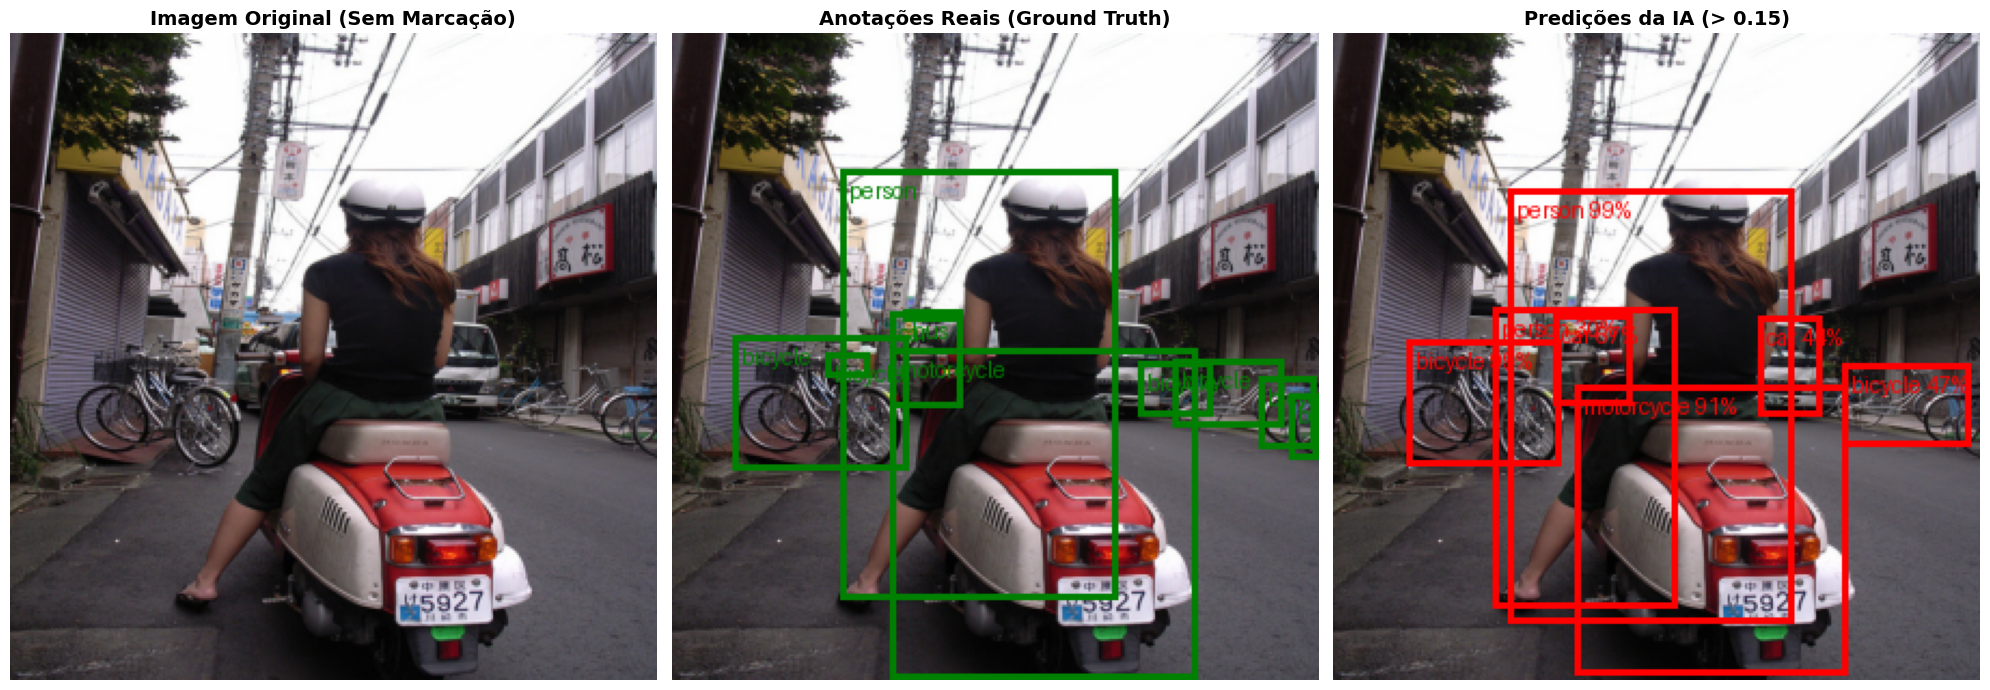


✅ Fluxo finalizado! A comparação visual tripla está salva no Drive em: /content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_SSD/Treino_ssd_2026-07-31_19h08/Teste_Final/val_batch0_comparacao_lado_a_lado.jpg


In [8]:
import matplotlib.pyplot as plt
import torchvision.transforms.functional as F
from torchvision.utils import draw_bounding_boxes
import cv2
import torch

# 1. Inverter o dicionário que criamos na classe do Dataset (ID -> Nome da Classe)
id_para_nome = {v: k for k, v in train_dataset.class_to_id.items()}

def ajustar_e_clampar_boxes(boxes, largura, altura):
    """
    Trata as coordenadas das caixas: se estiverem normalizadas (0 a 1),
    escala para o tamanho real da imagem. Garante que fiquem dentro dos limites do tensor.
    """
    if len(boxes) == 0:
        return boxes

    # Clonar para não alterar o tensor original do lote
    boxes_ajustadas = boxes.clone().detach().cpu()

    # CORREÇÃO DE ESCALA: Se o valor máximo for <= 1.01, significa que estão normalizadas.
    # Multiplicamos pelo tamanho absoluto da imagem no lote (ex: 300)
    if boxes_ajustadas.max() <= 1.01:
        boxes_ajustadas[:, [0, 2]] *= largura
        boxes_ajustadas[:, [1, 3]] *= altura

    # Garantir que nenhuma caixa extrapole os limites do tamanho do tensor da imagem
    boxes_ajustadas[:, [0, 2]] = boxes_ajustadas[:, [0, 2]].clamp(min=0, max=largura)
    boxes_ajustadas[:, [1, 3]] = boxes_ajustadas[:, [1, 3]].clamp(min=0, max=altura)

    # O draw_bounding_boxes exige formato inteiro (int64) para os pixels
    return boxes_ajustadas.to(torch.int64)

def preparar_imagem(img_tensor, boxes, labels, cor="red"):
    """
    Desenha as caixas na imagem e retorna o array NumPy pronto para o Matplotlib.
    Substitui a função anterior para permitir plotagem lado a lado.
    """
    # Desnormalizar a imagem de (0-1) para uint8 (0-255)
    img_uint8 = (img_tensor.detach().cpu() * 255).to(torch.uint8)

    altura, largura = img_uint8.shape[1], img_uint8.shape[2]

    # Ajustar a escala e formato das caixas antes do desenho
    boxes_prontas = ajustar_e_clampar_boxes(boxes, largura, altura)

    if len(boxes_prontas) > 0 and len(labels) == len(boxes_prontas):
        img_desenhada = draw_bounding_boxes(img_uint8, boxes_prontas, labels, colors=cor, width=3)
    else:
        img_desenhada = img_uint8

    # Converter formato do PyTorch (C, H, W) para formato Matplotlib (H, W, C)
    return img_desenhada.permute(1, 2, 0).numpy()

print(f"📊 Gerando visualizações de inferência...")
print("-" * 60)

# Colocar o modelo em modo de avaliação e extrair um lote de teste
model.eval()
images, targets = next(iter(test_loader))
images_gpu = list(img.to(device) for img in images)

with torch.no_grad():
    predictions = model(images_gpu)

# Analisar a primeira imagem do lote de testes
img_alvo = images[0]

# --- PREPARAR ANOTAÇÕES REAIS (GROUND TRUTH) ---
reais_boxes = targets[0]["boxes"]
reais_labels = [id_para_nome.get(l.item(), f"ID {l.item()}") for l in targets[0]["labels"]]

# --- PREPARAR PREDIÇÕES DA IA ---
pred_boxes = predictions[0]["boxes"]
pred_scores = predictions[0]["scores"]
pred_labels_ids = predictions[0]["labels"]

# CORREÇÃO DE CONFIANÇA
limiar_confianca = 0.15

indices_confiaveis = pred_scores > limiar_confianca
pred_boxes_filtradas = pred_boxes[indices_confiaveis]
pred_scores_filtrados = pred_scores[indices_confiaveis]
pred_labels_filtrados = pred_labels_ids[indices_confiaveis]

print(f"🔍 Total de predições cruas geradas pelo SSD: {len(pred_scores)}")
print(f"🎯 Predições que passaram no filtro atual (> {limiar_confianca}): {len(pred_scores_filtrados)}")

# Criar os rótulos de texto com a porcentagem de certeza
labels_predicao = [
    f"{id_para_nome.get(l.item(), f'ID {l.item()}')} {s.item()*100:.0f}%"
    for l, s in zip(pred_labels_filtrados, pred_scores_filtrados)
]

print("\n>>> INFERÊNCIA PRÁTICA (Original vs Ground Truth vs Predições)")

# 1. Obter os arrays das imagens preparadas com e sem caixas
img_original_np = preparar_imagem(img_alvo, torch.empty((0, 4)), [])
img_gt_np = preparar_imagem(img_alvo, reais_boxes, reais_labels, cor="green")
img_pred_np = preparar_imagem(img_alvo.cpu(), pred_boxes_filtradas.cpu(), labels_predicao, cor="red")

# 2. Criar a estrutura com 3 colunas (Lado a Lado)
fig, ax = plt.subplots(1, 3, figsize=(20, 7))

# Coluna 1: Imagem Original (sem marcação)
ax[0].imshow(img_original_np)
ax[0].set_title("Imagem Original (Sem Marcação)", fontsize=14, fontweight='bold')
ax[0].axis("off")

# Coluna 2: Anotações Reais (Ground Truth)
ax[1].imshow(img_gt_np)
ax[1].set_title("Anotações Reais (Ground Truth)", fontsize=14, fontweight='bold')
ax[1].axis("off")

# Coluna 3: Predição da IA
ax[2].imshow(img_pred_np)
ax[2].set_title(f"Predições da IA (> {limiar_confianca})", fontsize=14, fontweight='bold')
ax[2].axis("off")

plt.tight_layout()

# Salvar a figura combinada diretamente no Drive
caminho_comparacao = f"{pasta_teste_drive}/val_batch0_comparacao_lado_a_lado.jpg"
plt.savefig(caminho_comparacao, bbox_inches='tight', dpi=150)

# Exibir no Colab
plt.show()

print(f"\n✅ Fluxo finalizado! A comparação visual tripla está salva no Drive em: {caminho_comparacao}")